# Lab 10: Odometry and gyroscope localization

The analysis below follows Step 4 of the lab. Run A used encoder heading and Run B used gyro heading. The logged positions are the robot's own estimates, not an independent measurement of its path.


In [9]:
from pathlib import Path
import csv
import math
import numpy as np
import matplotlib.pyplot as plt

folders = [Path.cwd() / "data", Path.cwd() / "w10" / "data"]
data_folder = next(folder for folder in folders if folder.exists())

# Waypoints in cm; the robot starts at (0, 0).
waypoints = [
    (50, 0), (50, -100), (0, -100), (0, -50), (50, -50),
    (-30, 0), (-80, 0), (-80, -100), (-30, -100), (-30, 0)
]
radius_cm = 4.2
base_cm = 19.4
ticks_per_second = 3906

# Gyro values measured for this robot.
gyro_bias_mdeg_s = 140.0
scale_factor = 0.0035

def read_run(letter):
    rows = []
    file = data_folder / f"lab10_log_{letter}.txt"
    with file.open(newline="") as log:
        for line_number, values in enumerate(csv.reader(log), start=1):
            if len(values) != 9:
                raise ValueError(f"{file.name}, line {line_number}: expected 9 values")
            values = [float(value) for value in values]
            rows.append({
                "time_ms": values[0],
                "segment": int(values[1]),
                "left_deg": values[2],
                "right_deg": values[3],
                "gz_mdeg_s": values[4],
                "gyro_ticks": values[5],
                "x_cm": values[6],
                "y_cm": values[7],
                "course_rad": values[8],
            })
    return rows

runs = {"A": read_run("A"), "B": read_run("B")}
starts = [(0.0, 0.0)] + waypoints[:-1]
course_ref = [math.atan2(y - y0, x - x0)
              for (x0, y0), (x, y) in zip(starts, waypoints)]
path_ref = [math.hypot(x - x0, y - y0)
            for (x0, y0), (x, y) in zip(starts, waypoints)]


In [10]:
def wrap(angle):
    return math.atan2(math.sin(angle), math.cos(angle))

def mean_angle(values):
    return math.atan2(sum(math.sin(value) for value in values),
                      sum(math.cos(value) for value in values))

def follow_path(distances, courses):
    x = 0.0
    y = 0.0
    xs = []
    ys = []
    for distance, course in zip(distances, courses):
        x += distance * math.cos(course)
        y += distance * math.sin(course)
        xs.append(x)
        ys.append(y)
    return xs, ys

def distance_to_route(x, y):
    nearest_distance = float("inf")
    for start, end in zip(starts, waypoints):
        dx = end[0] - start[0]
        dy = end[1] - start[1]
        fraction = ((x - start[0]) * dx + (y - start[1]) * dy) / (dx * dx + dy * dy)
        fraction = min(1.0, max(0.0, fraction))
        nearest_x = start[0] + fraction * dx
        nearest_y = start[1] + fraction * dy
        nearest_distance = min(nearest_distance, math.hypot(x - nearest_x, y - nearest_y))
    return nearest_distance

results = {}
for name, rows in runs.items():
    # The wheel angles are cumulative, so their changes give each step's path.
    wheel_path = [(row["right_deg"] + row["left_deg"]) * radius_cm * math.pi / 360
                  for row in rows]
    path_step = [0.0] + [later - earlier for earlier, later in zip(wheel_path, wheel_path[1:])]

    # Recompute encoder course from wheel angles.
    course_odom = [(row["right_deg"] - row["left_deg"])
                   * radius_cm / base_cm * math.pi / 180 for row in rows]

    # Recompute gyro course with the measured bias shown in the parameter table and the QRS scale setting.
    rate = [(row["gz_mdeg_s"] / 1000 - gyro_bias_mdeg_s / 1000)
            / (1 + scale_factor) for row in rows]

    course_gyro = [0.0]
    for previous, current, current_rate in zip(rows, rows[1:], rate[1:]):
        dt = (current["gyro_ticks"] - previous["gyro_ticks"]) / ticks_per_second
        course_gyro.append(course_gyro[-1] + current_rate * dt * math.pi / 180)

    course_logged = [row["course_rad"] for row in rows]
    encoder_path = follow_path(path_step, course_odom)
    gyro_path = follow_path(path_step, course_gyro)

    segment_rows = {segment: [] for segment in range(len(waypoints))}
    for index, row in enumerate(rows):
        row["path_step"] = path_step[index]
        segment_rows[row["segment"]].append(index)

    segment_results = []
    for segment, indices in segment_rows.items():
        moving = [i for i in indices if abs(path_step[i]) > 1]
        course_mean = mean_angle([course_logged[i] for i in moving])
        course_error = wrap(course_mean - course_ref[segment])
        path_length = sum(path_step[i] for i in indices)
        last = rows[indices[-1]]
        segment_results.append({
            "course_mean_rad": course_mean,
            "course_error_rad": course_error,
            "path_cm": path_length,
            "path_error_cm": path_length - path_ref[segment],
            "endpoint_error_cm": math.hypot(
                last["x_cm"] - waypoints[segment][0],
                last["y_cm"] - waypoints[segment][1]),
        })

    route_error = [[] for _ in waypoints]
    for row in rows:
        route_error[row["segment"]].append(distance_to_route(row["x_cm"], row["y_cm"]))

    results[name] = {
        "rows": rows,
        "path_step": path_step,
        "course_logged": course_logged,
        "course_odom": course_odom,
        "course_gyro": course_gyro,
        "encoder_path": encoder_path,
        "gyro_path": gyro_path,
        "segments": segment_results,
        "route_error": [max(values) if values else 0 for values in route_error],
        "path_total": sum(path_step),
    }

comparison = []
for segment in range(len(waypoints)):
    a = results["A"]["segments"][segment]
    b = results["B"]["segments"][segment]
    comparison.append({
        "segment": segment + 1,
        "course_ref": math.degrees(course_ref[segment]),
        "course_A": math.degrees(a["course_mean_rad"]),
        "course_B": math.degrees(b["course_mean_rad"]),
        "d_course_A": math.degrees(a["course_error_rad"]),
        "d_course_B": math.degrees(b["course_error_rad"]),
        "path_ref": path_ref[segment],
        "path_A": a["path_cm"],
        "path_B": b["path_cm"],
        "d_path_A": a["path_error_cm"],
        "d_path_B": b["path_error_cm"],
    })

mean_abs_course_A = np.mean([abs(row["d_course_A"]) for row in comparison])
mean_abs_course_B = np.mean([abs(row["d_course_B"]) for row in comparison])
planned_length = sum(path_ref)


In [11]:
# Step 4.2: compare the on-robot estimates with the offline calculations.
for name, result in results.items():
    rows = result["rows"]
    if name == "A":
        offline_course = result["course_odom"]
        offline_path = result["encoder_path"]
        course_difference = max(abs(math.degrees(wrap(logged - encoder)))
                                for logged, encoder in zip(result["course_logged"], result["course_odom"]))
        method = "encoder course"
    else:
        offline_course = result["course_gyro"]
        offline_path = result["gyro_path"]
        course_difference = max(abs(math.degrees(wrap(logged - gyro)))
                                for logged, gyro in zip(result["course_logged"], result["course_gyro"]))
        method = "gyro course"
    position_difference = max(math.hypot(x - row["x_cm"], y - row["y_cm"])
                              for x, y, row in zip(offline_path[0], offline_path[1], rows))
    gap = [math.degrees(wrap(gyro - encoder))
           for gyro, encoder in zip(result["course_gyro"], result["course_odom"])]
    encoder_end = (result["encoder_path"][0][-1], result["encoder_path"][1][-1])
    gyro_end = (result["gyro_path"][0][-1], result["gyro_path"][1][-1])
    endpoint_gap = math.dist(encoder_end, gyro_end)
    # print(f"Run {name}: offline {method} vs logged x,y max difference ")
    #       f"{position_difference:.1f} cm; logged course vs offline course max difference "
    #       f"{course_difference:.1f}°.")
    print(f"Run {name}: offline gyro vs encoder: mean heading gap "
          f"{np.mean([abs(value) for value in gap]):.1f}°, max {max(abs(value) for value in gap):.1f}°; "
          f"final path endpoints {endpoint_gap:.1f} cm apart.")

# Deliverables comparison table, rendered as a notebook table.
from IPython.display import Markdown, display

table_lines = [
    "| Seg. | course_ref (°) | course A (°) | course B (°) | d_course A / B (°) | path_ref (cm) | path A (cm) | path B (cm) | d_path A / B (cm) |",
    "|---:|---:|---:|---:|---:|---:|---:|---:|---:|",
]
for row in comparison:
    table_lines.append(
        f"| {row['segment']} | {row['course_ref']:.1f} | {row['course_A']:.1f} | {row['course_B']:.1f} | "
        f"{row['d_course_A']:+.1f} / {row['d_course_B']:+.1f} | {row['path_ref']:.1f} | "
        f"{row['path_A']:.1f} | {row['path_B']:.1f} | {row['d_path_A']:+.1f} / {row['d_path_B']:+.1f} |"
    )
table_lines.append(
    f"| Summary |  |  |  | mean abs: {mean_abs_course_A:.1f} / {mean_abs_course_B:.1f} | "
    f"total: {planned_length:.1f} | {results['A']['path_total']:.1f} | {results['B']['path_total']:.1f} | "
    f"total error: {results['A']['path_total']-planned_length:+.1f} / "
    f"{results['B']['path_total']-planned_length:+.1f} cm "
    f"({(results['A']['path_total']/planned_length-1)*100:+.1f}% / "
    f"{(results['B']['path_total']/planned_length-1)*100:+.1f}%) |"
)
display(Markdown("\n".join(table_lines)))

print("\nFinal errors relative to the last waypoint and segment direction:")
for name, result in results.items():
    last = result["rows"][-1]
    position_error = math.hypot(last["x_cm"] - waypoints[-1][0], last["y_cm"] - waypoints[-1][1])
    course_error = math.degrees(wrap(last["course_rad"] - course_ref[-1]))
    print(f"Run {name}: position error {position_error:.2f} cm; course error {course_error:+.1f}°.")



Run A: offline gyro vs encoder: mean heading gap 11.9°, max 28.9°; final path endpoints 13.9 cm apart.
Run B: offline gyro vs encoder: mean heading gap 4.3°, max 14.1°; final path endpoints 12.6 cm apart.


| Seg. | course_ref (°) | course A (°) | course B (°) | d_course A / B (°) | path_ref (cm) | path A (cm) | path B (cm) | d_path A / B (cm) |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 1 | 0.0 | 0.8 | 1.3 | +0.8 / +1.3 | 50.0 | 48.0 | 48.6 | -2.0 / -1.4 |
| 2 | -90.0 | -87.1 | -86.6 | +2.9 / +3.4 | 100.0 | 100.9 | 101.2 | +0.9 / +1.2 |
| 3 | 180.0 | -171.8 | -175.2 | +8.2 / +4.8 | 50.0 | 51.2 | 51.3 | +1.2 / +1.3 |
| 4 | 90.0 | 95.5 | 94.8 | +5.5 / +4.8 | 50.0 | 51.7 | 52.1 | +1.7 / +2.1 |
| 5 | 0.0 | 5.8 | 5.2 | +5.8 / +5.2 | 50.0 | 50.8 | 50.5 | +0.8 / +0.5 |
| 6 | 148.0 | 149.0 | 149.8 | +1.0 / +1.8 | 94.3 | 99.6 | 100.5 | +5.3 / +6.2 |
| 7 | 180.0 | 174.5 | 174.8 | -5.5 / -5.2 | 50.0 | 52.5 | 50.9 | +2.5 / +0.9 |
| 8 | -90.0 | -93.8 | -91.6 | -3.8 / -1.6 | 100.0 | 106.3 | 102.8 | +6.3 / +2.8 |
| 9 | 0.0 | -0.3 | -5.6 | -0.3 / -5.6 | 50.0 | 53.6 | 55.5 | +3.6 / +5.5 |
| 10 | 90.0 | 87.7 | 88.3 | -2.3 / -1.7 | 100.0 | 102.0 | 103.6 | +2.0 / +3.6 |
| Summary |  |  |  | mean abs: 3.6 / 3.5 | total: 694.3 | 716.6 | 717.1 | total error: +22.3 / +22.7 cm (+3.2% / +3.3%) |


Final errors relative to the last waypoint and segment direction:
Run A: position error 2.72 cm; course error -9.9°.
Run B: position error 2.86 cm; course error -16.1°.


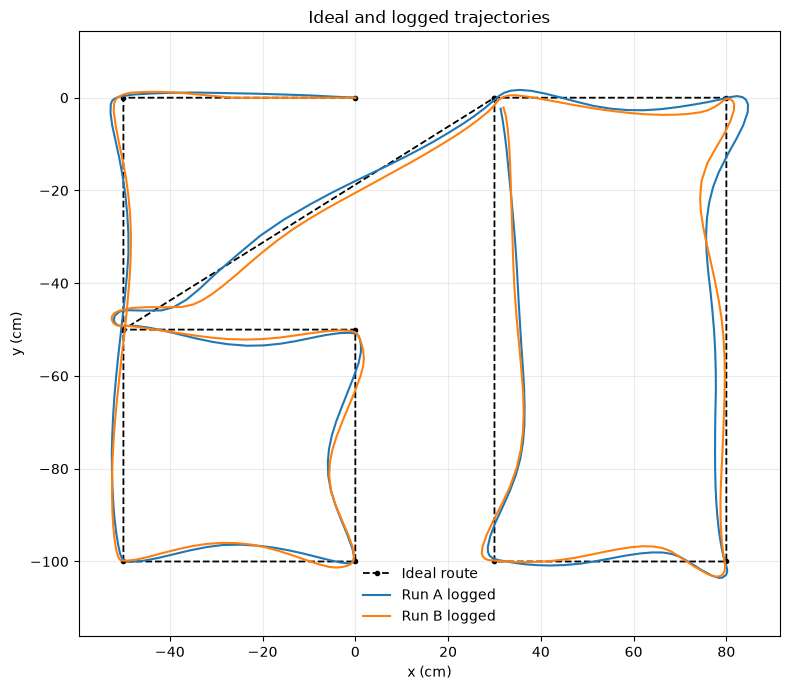

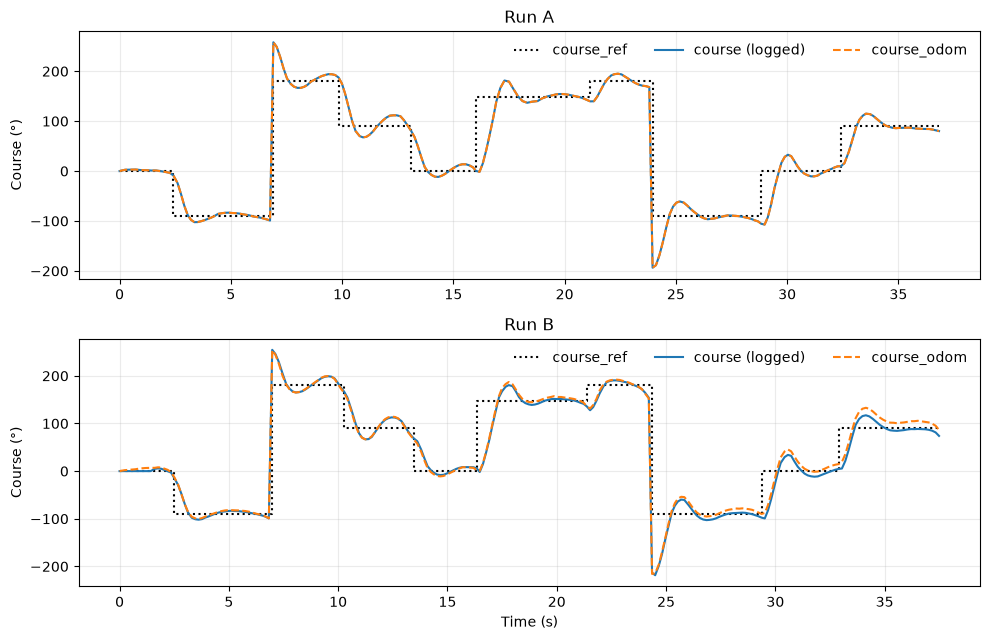

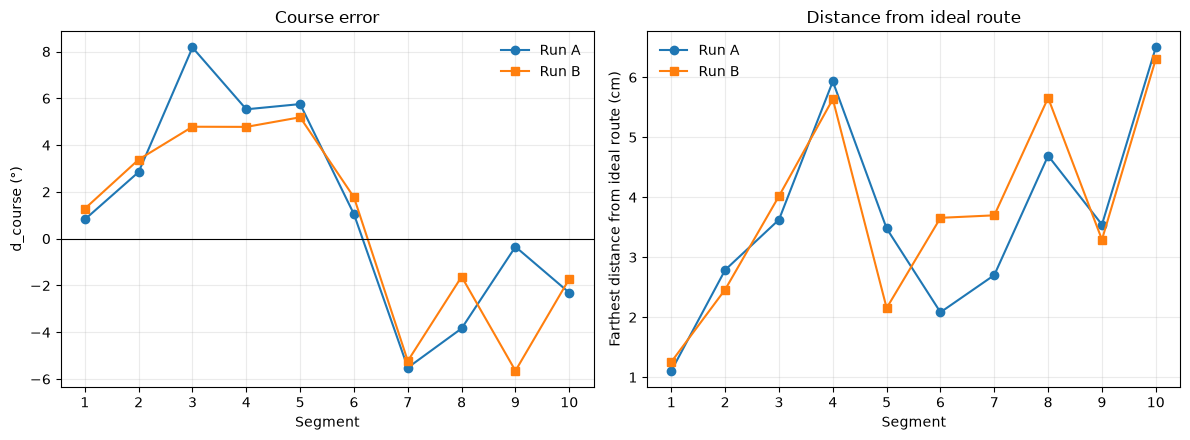

In [12]:
# Step 4.1: logged x,y and ideal route on one figure; both axes are flipped for display.
fig, ax = plt.subplots(figsize=(8, 7))
route = [(0, 0)] + waypoints
ax.plot([-point[0] for point in route], [point[1] for point in route], "k--o",
        ms=3, lw=1.3, label="Ideal route")
for name, result in results.items():
    rows = result["rows"]
    ax.plot([-row["x_cm"] for row in rows], [row["y_cm"] for row in rows],
            lw=1.5, label=f"Run {name} logged")
ax.set_xlabel("x (cm)")
ax.set_ylabel("y (cm)")
ax.set_title("Ideal and logged trajectories")
ax.set_aspect("equal", adjustable="datalim")
ax.grid(alpha=0.25)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

# Step 4.3: course(t) and course_odom(t) over the ideal course staircase.
fig, axes = plt.subplots(2, 1, figsize=(10, 6.5))
for ax, name in zip(axes, ("A", "B")):
    result = results[name]
    rows = result["rows"]
    time_s = [(row["time_ms"] - rows[0]["time_ms"]) / 1000 for row in rows]
    ideal = [math.degrees(course_ref[row["segment"]]) for row in rows]
    ax.step(time_s, ideal, where="post", color="black", ls=":", label="course_ref")
    logged_near_ref = [math.degrees(course_ref[row["segment"]] +
                                    wrap(value - course_ref[row["segment"]]))
                       for row, value in zip(rows, result["course_logged"])]
    odom_near_ref = [math.degrees(course_ref[row["segment"]] +
                                  wrap(value - course_ref[row["segment"]]))
                     for row, value in zip(rows, result["course_odom"])]
    ax.plot(time_s, logged_near_ref,
            label="course (logged)")
    ax.plot(time_s, odom_near_ref,
            ls="--", label="course_odom")
    ax.set_title(f"Run {name}")
    ax.set_ylabel("Course (°)")
    ax.grid(alpha=0.25)
    ax.legend(frameon=False, ncol=3)
axes[-1].set_xlabel("Time (s)")
fig.tight_layout()
plt.show()

# Step 4.5: course error and distance from the logged x,y to the ideal route by segment.
segments = list(range(1, len(waypoints) + 1))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(segments, [row["d_course_A"] for row in comparison], "o-", label="Run A")
axes[0].plot(segments, [row["d_course_B"] for row in comparison], "s-", label="Run B")
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_ylabel("d_course (°)")
axes[0].set_title("Course error")
axes[0].legend(frameon=False)
for name, marker in (("A", "o-"), ("B", "s-")):
    axes[1].plot(segments, results[name]["route_error"], marker, label=f"Run {name}")
axes[1].set_ylabel("Farthest distance from ideal route (cm)")
axes[1].set_title("Distance from ideal route")
axes[1].legend(frameon=False)
for ax in axes:
    ax.set_xlabel("Segment")
    ax.set_xticks(segments)
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


## Conclusion

Run B is marginally closer in mean course error (3.54° versus 3.62°), while Run A is marginally closer in total path error (+3.2% versus +3.3%). The difference is too small to show a clear winner. Both path estimates come from the wheel encoders in both runs, which is why their path errors are similar even though their course estimates use different sensors. The logged distance from the ideal route stays bounded below 7 cm, with its largest increase on the final segment.

For Run A, the changing segment errors could come from wheel slip, but these logs do not separate slip from an incorrect wheel-base value. Run B's logged gyro course differs from the encoder course, but the logs alone cannot determine whether that difference came from gyro bias, scale error, wheel slip, or the wheel-base value. The offline recomputations show the sensor disagreement, but they do not identify one cause as dominant.

A complementary filter could combine the two: `course = 0.01 * course_odom + 0.99 * (course + gyro_inc)`. The gyro would follow each turn, while encoder heading would slowly correct gyro drift.
